Summarize temporal organization by ranking each transition among its available alternatives. Calculate participant summaries, compare selections and save the figure.

## Settings

`data_paths` and `data_labels` select saved responses to compare. An explicit `data_path`
uses the existing single-input mode. Set the condition queries and analysis controls below.
See the [overview](../templates.qmd#from-a-template-to-a-run) for input files, parameter injection and independent jobs.


In [1]:
#| code-summary: "1 — Set the parameters for this run"


# Response files
data_path = None  # A supplied single path takes precedence over data_paths.
data_paths = [
    "data/Dupertuys2026.h5",
    "data/simulations/Dupertuys2026_CMR_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_source_only_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_broad_demo_best_of_3.h5",
]
data_labels = ["Observed", "CMR", "Source-only eCMR", "Broader eCMR"]

# Saved results
output_dir = "results/lagrank"


# Analysis and uncertainty settings
confidence_level = 0.95
plot_seed = 0  # NumPy seed for bootstrap displays.

max_subjects = 0
figure_dir = None
figure_str = "lagrank"  # Empty displays the figure without saving it.


# Condition selection
trial_query = None  # When supplied, use this one selection instead of trial_queries.
trial_queries = [
    "jnp.equal(data['list_type'], 1)",
    "jnp.equal(data['list_type'], 2)",
    "jnp.equal(data['list_type'], 3)",
]
labels = ["Mixed", "Pure emotional", "Pure neutral"]
selection_label = "Selected lists"
contrast_name = None  # Legend title for the selected comparisons.
complete_lists_only = True


# Figure appearance
color_cycle = None
ylim = None
yticks = None


# Repeated-item capacity
size = 3  # Maximum study positions occupied by one item.


In [2]:
#| code-summary: "2 — Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "d919f1ad6aeacc7a36c40b96e365316219a7f40a"
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
        ]
    )
    from jaxcmr.colab import fetch_inputs

    fetch_inputs(
        ([data_path] if data_path is not None else data_paths), revision=revision
    )


In [3]:
#| code-summary: "3 — Import packages"

import csv
from pathlib import Path

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate

from jaxcmr.analyses.lagrank import percentile_rank, plot_lagrank, subject_lagrank
from jaxcmr.helpers import generate_trial_mask, load_data, save_figure


## Select the observations

`recalls` contains one-based study-position codes; zero marks unused response slots.
`pres_itemnos` gives within-list item codes; zero marks a padded study slot. The arrays
must retain those meanings when you substitute another dataset. SPC, PNR and lag-CRP
also use `listLength` to label their positions.

The queries choose the observations. `complete_lists_only` additionally excludes lists
with padded study slots. The printed counts report the resulting selections. Each curve first
summarizes a participant's selected lists; participants then receive equal weight.

In [4]:
#| code-summary: "4 — Resolve input paths, conditions and output settings"

np.random.seed(plot_seed)
output_dir = Path(output_dir)
figure_dir = Path(figure_dir) if figure_dir is not None else output_dir
output_dir.mkdir(parents=True, exist_ok=True)

queries = trial_queries if trial_query is None else [trial_query]
condition_labels = labels if trial_query is None else [selection_label]
input_paths = [data_path] if data_path is not None else data_paths
input_labels = [selection_label] if data_path is not None else data_labels
if len(queries) != len(condition_labels) or len(input_paths) != len(input_labels):
    raise ValueError("Supply a label for each input and each condition query.")


In [5]:
#| code-summary: "5 — Load the supplied response datasets"

datasets = [load_data(str(path), max_subjects=max_subjects) for path in input_paths]


In [6]:
#| code-summary: "6 — Select observations and report participant counts"

masks_by_dataset = []
for dataset, dataset_label in zip(datasets, input_labels):
    condition_masks = [generate_trial_mask(dataset, query) for query in queries]
    if complete_lists_only:
        condition_masks = [
            condition_mask & jnp.all(dataset["pres_itemnos"] > 0, axis=1)
            for condition_mask in condition_masks
        ]
    masks_by_dataset.append(condition_masks)
    for condition_label, condition_mask in zip(condition_labels, condition_masks):
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        print(
            f"{dataset_label} / {condition_label}: {int(condition_mask.sum())} lists, {len(participant_ids)} participants"
        )
        if not len(participant_ids):
            raise ValueError(
                "The selected input and condition contain no eligible lists."
            )
data, trial_masks = datasets[0], masks_by_dataset[0]


Observed / Mixed: 246 lists, 123 participants
Observed / Pure emotional: 122 lists, 122 participants
Observed / Pure neutral: 123 lists, 123 participants
CMR / Mixed: 2460 lists, 123 participants
CMR / Pure emotional: 1220 lists, 122 participants
CMR / Pure neutral: 1230 lists, 123 participants
Source-only eCMR / Mixed: 2460 lists, 123 participants
Source-only eCMR / Pure emotional: 1220 lists, 122 participants
Source-only eCMR / Pure neutral: 1230 lists, 123 participants
Broader eCMR / Mixed: 2460 lists, 123 participants
Broader eCMR / Pure emotional: 1220 lists, 122 participants
Broader eCMR / Pure neutral: 1230 lists, 123 participants


In [7]:
#| code-summary: "7 — Require complete study lists for temporal analysis"

presentations = np.asarray(data["pres_itemnos"])

for dataset, masks in zip(datasets, masks_by_dataset):
    if any(
        bool(jnp.any(mask & jnp.any(dataset["pres_itemnos"] == 0, axis=1)))
        for mask in masks
    ):
        raise ValueError("This temporal procedure requires complete study lists.")


## Rank one chosen transition

Take absolute lags to the available alternatives. A smaller distance receives a higher score;
ties receive their midpoint rank. Fewer than two available alternatives gives an undefined score.
The uniform-choice expectation among these eligible alternatives is 0.5; that reference depends
on this definition of the choice set.

This small illustration uses an unrepeated list. The full calculation handles repeated presentations using `size`.


In [8]:
#| code-summary: "8 — Rank one transition among its alternatives"

selected = np.logical_or.reduce([np.asarray(mask) for mask in trial_masks])
eligible = selected & ((np.asarray(data["recalls"]) > 0).sum(axis=1) >= 2)
unrepeated = np.array(
    [
        len(np.unique(items[items > 0])) == np.count_nonzero(items)
        for items in presentations
    ]
)
eligible_rows = np.flatnonzero(eligible & unrepeated)
if not len(eligible_rows):
    print(
        "No unrepeated list with two recalls to illustrate; transition-based summaries are undefined for this selection."
    )
else:
    row = int(eligible_rows[0])
    recall = np.asarray(data["recalls"])[row].astype(int)
    recall = recall[recall > 0]
    previous, chosen = recall[:2]
    available = np.flatnonzero(presentations[row] > 0) + 1
    available = available[available != previous]
    print(
        tabulate(
            {
                "Available study position": available,
                "Lag from previous recall": available - previous,
                "Chosen next": available == chosen,
            },
            headers="keys",
            floatfmt=".4g",
        )
    )
    print(f"Observed transition: {previous} to {chosen}; lag = {chosen - previous:+d}")

    distances = np.abs(available - previous)
    score = percentile_rank(jnp.asarray(abs(chosen - previous)), jnp.asarray(distances))
    print(f"Rank score for this transition: {float(score):.3f}")


  Available study position    Lag from previous recall    Chosen next
--------------------------  --------------------------  -------------
                         1                          -1              0
                         3                           1              0
                         4                           2              0
                         5                           3              0
                         6                           4              0
                         7                           5              0
                         8                           6              1
                         9                           7              0
                        10                           8              0
                        11                           9              0
                        12                          10              0
Observed transition: 2 to 8; lag = +6
Rank score for this transition: 0.400


## Summarize participants and plot

In [9]:
#| code-summary: "9 — Prepare the condition and dataset comparison panels"

panels = []
if data_path is not None:
    panels.append(
        {
            "datasets": [data] * len(queries),
            "trial_masks": trial_masks,
            "labels": condition_labels,
            "title": selection_label,
        }
    )
else:
    for condition_index, condition_label in enumerate(condition_labels):
        panels.append(
            {
                "datasets": datasets,
                "trial_masks": [masks[condition_index] for masks in masks_by_dataset],
                "labels": input_labels,
                "title": condition_label,
            }
        )


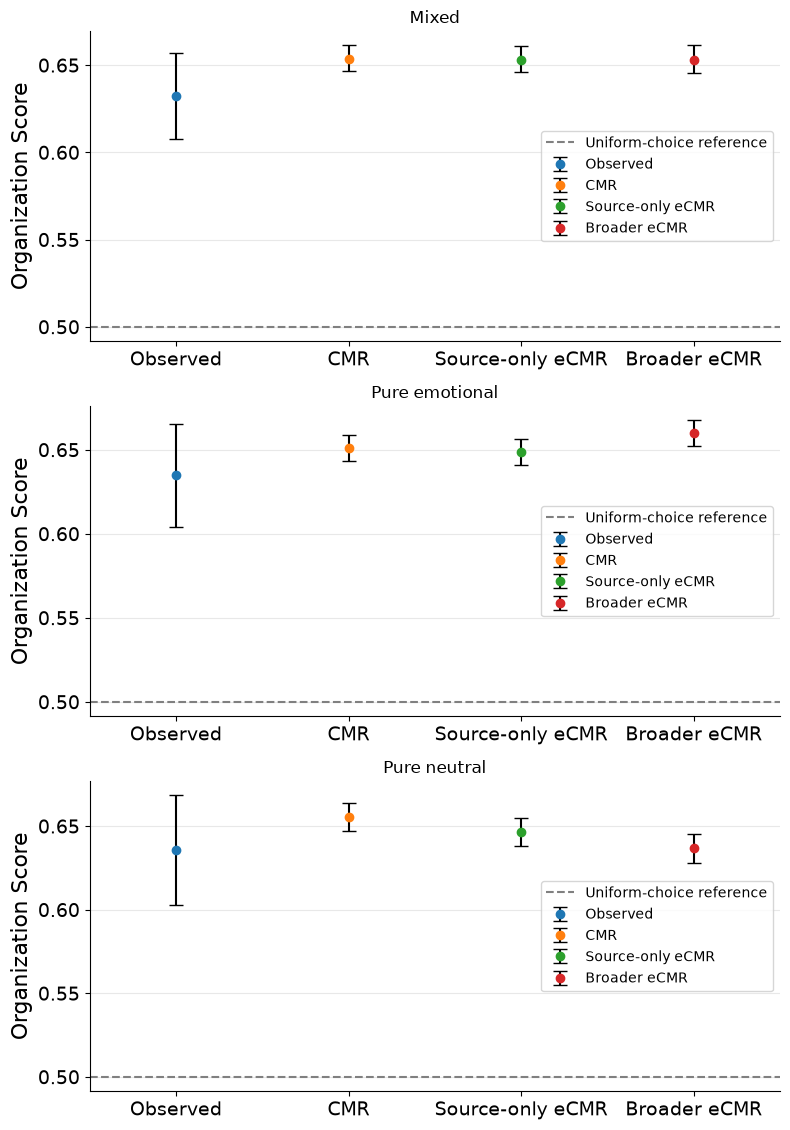

In [10]:
#| code-summary: "10 — Calculate, plot and save the selected comparison"

fig, axes = plt.subplots(len(panels), 1, figsize=(8, 3.8 * len(panels)), squeeze=False)
for ax, panel in zip(axes.ravel(), panels):
    panel_data = panel["datasets"]
    panel_masks = panel["trial_masks"]
    curve_labels = panel["labels"]
    title = panel["title"]
    plot_lagrank(
        panel_data,
        panel_masks,
        size=size,
        labels=curve_labels,
        contrast_name=contrast_name,
        color_cycle=color_cycle,
        confidence_level=confidence_level,
        axis=ax,
    )
    ax.axhline(0.5, color="grey", linestyle="--", label="Uniform-choice reference")
    ax.set_title(title)

    if ax.get_legend_handles_labels()[1]:
        ax.legend(title=contrast_name)
    if ylim is not None:
        ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)
save_figure(str(figure_dir), figure_str)


In [11]:
#| code-summary: "11 — Calculate and summarize participant scores"

participant_rows = []
for dataset, dataset_label, condition_masks in zip(
    datasets, input_labels, masks_by_dataset
):
    for condition_label, condition_mask in zip(condition_labels, condition_masks):
        participant_scores = np.asarray(
            subject_lagrank(dataset, condition_mask, size=size)
        )
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        participant_rows.extend(
            (dataset_label, condition_label, subject, score)
            for subject, score in zip(participant_ids, participant_scores)
        )
        print(
            f"{dataset_label} / {condition_label}: {np.isfinite(participant_scores).sum()} scores; mean {np.nanmean(participant_scores):.3f}"
        )


Observed / Mixed: 122 scores; mean 0.632


Observed / Pure emotional: 121 scores; mean 0.635


Observed / Pure neutral: 122 scores; mean 0.636
CMR / Mixed: 122 scores; mean 0.654


CMR / Pure emotional: 121 scores; mean 0.651


CMR / Pure neutral: 122 scores; mean 0.655
Source-only eCMR / Mixed: 122 scores; mean 0.653


Source-only eCMR / Pure emotional: 121 scores; mean 0.649
Source-only eCMR / Pure neutral: 122 scores; mean 0.646


Broader eCMR / Mixed: 122 scores; mean 0.653
Broader eCMR / Pure emotional: 121 scores; mean 0.660


Broader eCMR / Pure neutral: 122 scores; mean 0.637


In [12]:
#| code-summary: "12 — Save participant summaries as CSV"

with (output_dir / "participant_ranks.csv").open("w", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["Dataset", "Condition", "Subject", "Rank"])
    writer.writerows(participant_rows)


## Interpret and adapt

A mean above 0.5 indicates a preference for nearer eligible positions relative to uniform choice among the same alternatives. Inspect how many participants have a defined score. The scalar score discards direction and the detailed shape visible in lag-CRP.

